# Introduction to Qiskit

Qiskit Fall Fest 2026.

**What we will cover**

1. Qubits, circuits and state vectors
2. Single-qubit gates
3. Measurement and the Sampler
4. Multiple qubits and entanglement
5. The Qiskit pattern: Map, Optimize, Execute, Post-process
6. Expectation values and the Estimator
7. Parameterized circuits
8. Noise
9. Summary

Run the cells from top to bottom. Cells marked **Your turn** are for you to try.

In [ ]:
# Uncomment and run once if you still need to install dependencies, then restart the kernel.
# %pip install --upgrade 'qiskit[visualization]>=2.1.0' qiskit-aer numpy matplotlib pylatexenc

In [1]:
import numpy as np
import matplotlib.pyplot as plt

import qiskit
from qiskit import QuantumCircuit
from qiskit.circuit import Parameter
from qiskit.quantum_info import Statevector, SparsePauliOp, Operator
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit.visualization import plot_histogram, plot_bloch_multivector, array_to_latex

from qiskit_aer import AerSimulator
from qiskit_aer.primitives import SamplerV2 as Sampler, EstimatorV2 as Estimator

print("Qiskit version:", qiskit.__version__)

Qiskit version: 2.5.2


## 1. Qubits, circuits and state vectors

A classical bit is 0 or 1. A **qubit** can be in a superposition

$$|\psi\rangle = \alpha|0\rangle + \beta|1\rangle, \qquad |\alpha|^2 + |\beta|^2 = 1,$$

where $\alpha, \beta$ are complex amplitudes. The vector form is $|0\rangle = \begin{pmatrix}1\\0\end{pmatrix}$ and $|1\rangle = \begin{pmatrix}0\\1\end{pmatrix}$.

A **quantum circuit** is a list of gates applied to qubits, read left to right. Every qubit starts in $|0\rangle$. In Qiskit we create one with `QuantumCircuit(n)`.

In [13]:
# one qubit, no gates yet


We can ask Qiskit for the state vector that a circuit produces. This is only possible in simulation, never on real hardware.

In [14]:

# print("Amplitudes:", state.data)
# print("Probabilities of 0 and 1:", state.probabilities())

## 2. Single-qubit gates

Gates are the operations we apply to qubits. Each gate is a unitary matrix. The most common single-qubit gates:

| Gate | Method | Effect |
|---|---|---|
| X (NOT) | `qc.x(0)` | swaps $\lvert 0\rangle$ and $\lvert 1\rangle$ |
| H (Hadamard) | `qc.h(0)` | creates an equal superposition |
| Z | `qc.z(0)` | flips the sign of $\lvert 1\rangle$ |
| Y | `qc.y(0)` | rotation by $\pi$ about the y axis |
| S, T | `qc.s(0)`, `qc.t(0)` | phase gates |

### The X gate

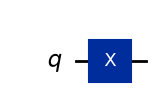

<IPython.core.display.Latex object>

In [15]:


display(qc.draw("mpl"))
display(Statevector(qc).draw("latex"))

### The Hadamard gate

$$H = \frac{1}{\sqrt{2}}\begin{pmatrix}1 & 1\\1 & -1\end{pmatrix}, \qquad H|0\rangle = \frac{|0\rangle + |1\rangle}{\sqrt{2}} = |+\rangle .$$

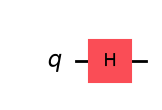

<IPython.core.display.Latex object>

<IPython.core.display.Latex object>

In [16]:


display(qc.draw("mpl"))
display(Statevector(qc).draw("latex"))

# The gate itself, as a matrix
array_to_latex(Operator(qc).data)

### Seeing states on the Bloch sphere

Any single-qubit state is a point on the Bloch sphere. $|0\rangle$ is the north pole, $|1\rangle$ is the south pole, and $|+\rangle$ lies on the x axis.

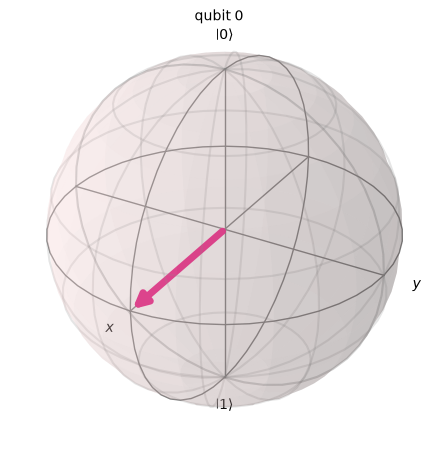

In [17]:

plot_bloch_multivector(Statevector(qc))

### Rotation gates

`rx`, `ry` and `rz` rotate the state about an axis by any angle. For example, `rx(pi/2)` rotates by 90 degrees about the x axis.

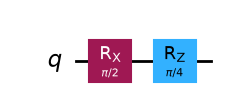

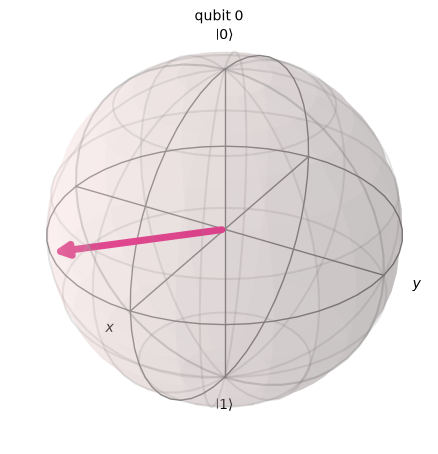

In [18]:


display(qc.draw("mpl"))
plot_bloch_multivector(Statevector(qc))

### Your turn 1

Prepare the state $|-\rangle = \frac{1}{\sqrt{2}}(|0\rangle - |1\rangle)$ using the gates above. Then run the check cell.

<details>
<summary>Hint</summary>

Start from $|1\rangle$ and apply a Hadamard, or start from $|+\rangle$ and flip the sign of $|1\rangle$.

</details>

In [ ]:
qc = QuantumCircuit(1)

# TODO: add your gates here

qc.draw("mpl")

In [ ]:
# Check your answer
if Statevector(qc).equiv(Statevector.from_label("-")):
    print("Correct! You prepared |->.")
else:
    print("Not yet. Print Statevector(qc) and compare with (|0> - |1>)/sqrt(2).")

## 3. Measurement and the Sampler

Reading out a qubit is a **measurement**. It always returns a classical 0 or 1, and the state collapses to that outcome. The probability of each outcome is the squared magnitude of its amplitude (the **Born rule**):

$$P(0) = |\alpha|^2, \qquad P(1) = |\beta|^2 .$$

One run of a circuit gives one outcome, so we repeat it many times. Each run is called a **shot**. In Qiskit, a **primitive** runs circuits for us. The **Sampler** returns the measured bitstrings.

First, a small helper that transpiles a circuit (more on that in section 5), runs it, and returns the counts.

In [23]:
backend = AerSimulator()
pm = generate_preset_pass_manager(optimization_level=1, backend=backend)
sampler = Sampler()

def get_counts(circuit, shots=1024):
    """Run a circuit with measurements on the simulator and return the counts."""
    isa = pm.run(circuit)
    result = sampler.run([isa], shots=shots).result()
    return result[0].data.meas.get_counts()

In [ ]:
qc = QuantumCircuit(1)
qc.h(0)
qc.measure_all()      # adds a measurement on every qubit, stored in a register called "meas"

display(qc.draw("mpl"))

counts = get_counts(qc, shots=1000)
print(counts)
plot_histogram(counts)

With only a few shots the split is noisy. With many shots it approaches the true 50-50 probabilities.

In [ ]:
for shots in [10, 100, 10000]:
    counts = get_counts(qc, shots=shots)
    print(f"{shots:>6} shots: P(0) = {counts.get('0', 0) / shots:.3f}")

A qubit that is not in an equal superposition gives unequal probabilities. Here `ry(theta)` rotates $|0\rangle$ toward $|1\rangle$, so $P(1) = \sin^2(\theta/2)$.

In [ ]:
theta = np.pi / 3

qc = QuantumCircuit(1)
qc.ry(theta, 0)
qc.measure_all()

counts = get_counts(qc, shots=5000)
print("Measured P(1):", counts.get("1", 0) / 5000)
print("Predicted P(1):", np.sin(theta / 2) ** 2)
plot_histogram(counts)

## 4. Multiple qubits and entanglement

With $n$ qubits the state has $2^n$ amplitudes. Two qubits live in the basis $|00\rangle, |01\rangle, |10\rangle, |11\rangle$.

**Qiskit ordering.** Qubit 0 is the *right-most* bit: $|q_1 q_0\rangle$. This is called little-endian. Applying X to qubit 0 therefore gives $|01\rangle$, not $|10\rangle$.

In [ ]:
qc = QuantumCircuit(2)
qc.x(0)

display(qc.draw("mpl"))
Statevector(qc).draw("latex")

### The CNOT gate

CNOT acts on two qubits: it flips the **target** if the **control** is $|1\rangle$, and does nothing otherwise. In Qiskit, `qc.cx(control, target)`.

### Entanglement: the Bell state

Apply H to qubit 0 to make a superposition, then use it as the control of a CNOT:

$$|00\rangle \xrightarrow{H_0} \frac{|00\rangle + |01\rangle}{\sqrt{2}} \xrightarrow{\text{CNOT}} \frac{|00\rangle + |11\rangle}{\sqrt{2}} .$$

In [ ]:
bell = QuantumCircuit(2)
bell.h(0)
bell.cx(0, 1)

display(bell.draw("mpl"))
Statevector(bell).draw("latex")

This state cannot be written as a product of two separate qubit states: the qubits are **entangled**. Neither qubit has a definite value alone, but they always agree. Measuring gives only `00` or `11`.

In [ ]:
bell_meas = bell.copy()
bell_meas.measure_all()

counts = get_counts(bell_meas, shots=2000)
print(counts)
plot_histogram(counts)

### Your turn 2

Build a three-qubit **GHZ state** $\frac{1}{\sqrt{2}}(|000\rangle + |111\rangle)$, measure it, and check that only `000` and `111` appear.

<details>
<summary>Hint</summary>

Start like the Bell state, then add another CNOT from qubit 1 to qubit 2.

</details>

In [ ]:
ghz = QuantumCircuit(3)

# TODO: add your gates here

ghz.measure_all()
ghz.draw("mpl")

In [ ]:
counts = get_counts(ghz, shots=2000)
print(counts)
print("Correct!" if set(counts) == {"000", "111"} else "Not yet: only 000 and 111 should appear.")
plot_histogram(counts)

## 5. The Qiskit pattern: Map, Optimize, Execute, Post-process

Every Qiskit workflow follows four steps, called a **Qiskit pattern**:

| Step | What you do | In this notebook |
|---|---|---|
| 1. Map | Express the problem as circuits and operators | build the circuit |
| 2. Optimize | Rewrite the circuit for the target backend | transpile |
| 3. Execute | Run it with a primitive | Sampler or Estimator |
| 4. Post-process | Turn raw results into an answer | histograms, plots |

We have already done steps 1, 3 and 4. Now let us look at step 2.

### Step 2: Transpilation

Real quantum computers support only a small set of native gates and have limited qubit connectivity. **Transpiling** rewrites our circuit into an equivalent one that the backend can actually run. To see this without a real device, we use a fake 5-qubit backend with typical hardware properties: native gates `rz`, `sx`, `x`, `cx`, and qubits connected in a line.

Native gates: ['cx', 'id', 'rz', 'sx', 'x', 'reset', 'delay', 'measure']


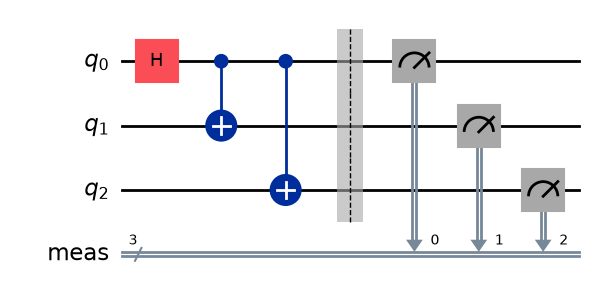

In [19]:
from qiskit.providers.fake_provider import GenericBackendV2
from qiskit.transpiler import CouplingMap

hw_like = GenericBackendV2(num_qubits=5, coupling_map=CouplingMap.from_line(5), seed=42)
print("Native gates:", hw_like.operation_names)

# A circuit that needs qubit 0 to interact with qubit 2 (not neighbours on a line)
qc = QuantumCircuit(3)
qc.h(0)
qc.cx(0, 1)
qc.cx(0, 2)
qc.measure_all()

display(qc.draw("mpl"))

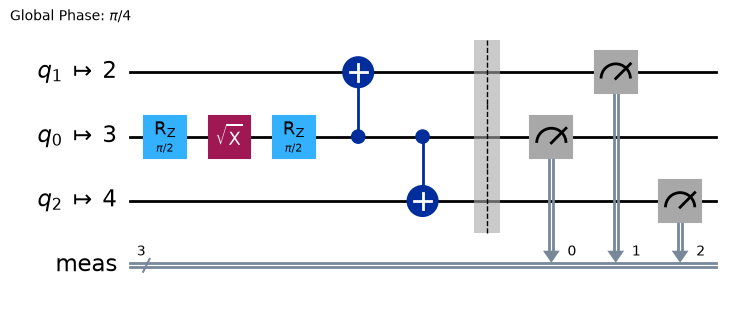

Gate counts: {'measure': 3, 'rz': 2, 'cx': 2, 'sx': 1, 'barrier': 1}
Depth: 6


In [20]:
pm_hw = generate_preset_pass_manager(optimization_level=1, backend=hw_like)
isa_qc = pm_hw.run(qc)

display(isa_qc.draw("mpl", idle_wires=False))
print("Gate counts:", dict(isa_qc.count_ops()))
print("Depth:", isa_qc.depth())

The transpiler replaced `h` by native gates, and chose which physical qubits to use. The optimization level controls how hard it tries to shrink the circuit: level 0 does the minimum, level 3 the most. Compare:

In [21]:
for level in range(4):
    pm_level = generate_preset_pass_manager(optimization_level=level, backend=hw_like)
    out = pm_level.run(qc)
    print(f"optimization_level={level}: depth={out.depth()}, gates={dict(out.count_ops())}")

optimization_level=0: depth=9, gates={'cx': 5, 'measure': 3, 'rz': 2, 'sx': 1, 'barrier': 1}
optimization_level=1: depth=6, gates={'measure': 3, 'rz': 2, 'cx': 2, 'sx': 1, 'barrier': 1}
optimization_level=2: depth=6, gates={'measure': 3, 'rz': 2, 'cx': 2, 'sx': 1, 'barrier': 1}
optimization_level=3: depth=6, gates={'measure': 3, 'rz': 2, 'cx': 2, 'sx': 1, 'barrier': 1}


The transpiled circuit still runs on our simulator, because it only uses standard gates. Let us execute it (step 3) and look at the result (step 4).

{'000': 1012, '111': 988}


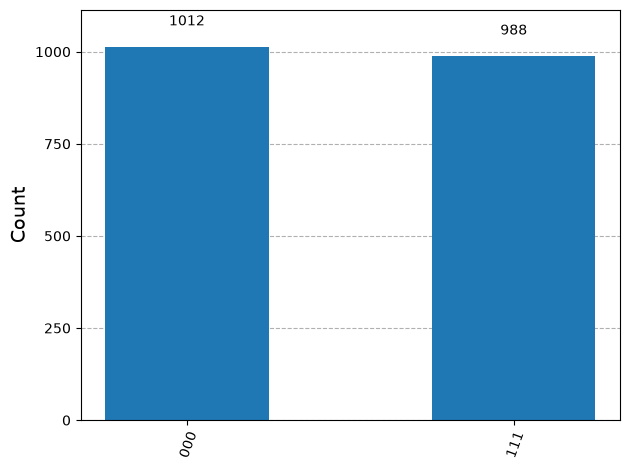

In [24]:
result = sampler.run([isa_qc], shots=2000).result()
counts = result[0].data.meas.get_counts()
print(counts)
plot_histogram(counts)

## 6. Expectation values and the Estimator

Sometimes we do not want the bitstrings. We want a number: the **expectation value** $\langle O\rangle$ of an **observable** $O$ in the state our circuit prepares. The **Estimator** primitive computes it directly.

Observables are built from Pauli operators with `SparsePauliOp`. For a single qubit, $Z = |0\rangle\langle 0| - |1\rangle\langle 1|$, so $\langle Z\rangle = P(0) - P(1)$.

**Ordering reminder:** in a Pauli string such as `"ZI"`, the right-most letter acts on qubit 0.

Circuits for the Estimator must **not** contain measurements.

In [25]:
estimator = Estimator()

# |+> state: P(0) = P(1) = 0.5, so <Z> = 0 and <X> = 1
qc_plus = QuantumCircuit(1)
qc_plus.h(0)

Z = SparsePauliOp("Z")
X = SparsePauliOp("X")

result = estimator.run([(qc_plus, [Z, X])]).result()
print("<Z>, <X> =", result[0].data.evs)

<Z>, <X> = [0. 1.]


## 7. Parameterized circuits

A circuit can contain symbolic `Parameter`s whose values we fill in later. This lets us build a circuit once and run it for many values, which is exactly the loop used by variational algorithms such as VQE on Day 2.

For $R_x(\theta)|0\rangle$ we expect $\langle Z\rangle = \cos\theta$.

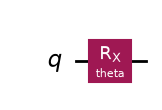

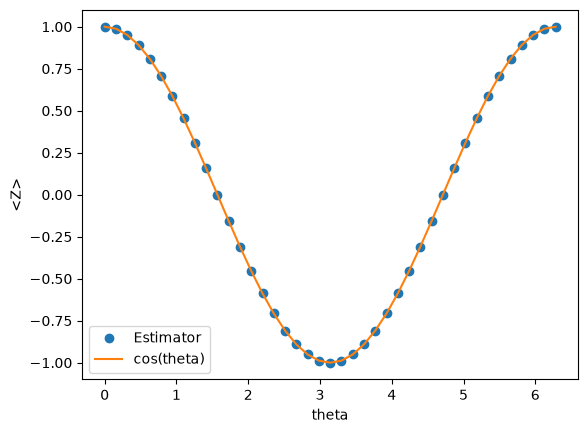

In [26]:
theta = Parameter("theta")

qc_param = QuantumCircuit(1)
qc_param.rx(theta, 0)

display(qc_param.draw("mpl"))

# One observable, many parameter values in a single call
thetas = np.linspace(0, 2 * np.pi, 41)
result = estimator.run([(qc_param, Z, thetas.reshape(-1, 1))]).result()
evs = result[0].data.evs

plt.plot(thetas, evs, "o", label="Estimator")
plt.plot(thetas, np.cos(thetas), "-", label="cos(theta)")
plt.xlabel("theta")
plt.ylabel("<Z>")
plt.legend()
plt.show()

You can also fix the parameters yourself with `assign_parameters`:

In [ ]:
bound = qc_param.assign_parameters({theta: np.pi / 2})
bound.draw("mpl")

## 9. Summary

| Idea | Qiskit |
|---|---|
| Create a circuit | `QuantumCircuit(n)` |
| Apply gates | `qc.h(0)`, `qc.x(0)`, `qc.cx(0, 1)`, `qc.rx(theta, 0)` |
| Add measurements | `qc.measure_all()` |
| Draw | `qc.draw("mpl")` |
| State vector (simulation only) | `Statevector(qc)` |
| Transpile for a backend | `generate_preset_pass_manager(...)` then `pm.run(qc)` |
| Bitstring counts | `Sampler` |
| Expectation values | `Estimator` with `SparsePauliOp` observables |
| Symbolic angles | `Parameter`, `assign_parameters` |


**Remember:** qubit 0 is the right-most bit, and the Qiskit pattern is Map, Optimize, Execute, Post-process.

### Where next

MORE ABOUT SPINS AND ENTAGLEMENT 